### Setups

In [1]:
import pandas as pd
from pathlib import Path
from sklearn.metrics import f1_score
import seaborn as sns
import matplotlib.pyplot as plt
import json
import os

os.makedirs("../figures/performance_comparison_fig4", exist_ok=True)

### Load data

In [2]:
DORN_PATH = Path("../../Experiments/dorn_warm/dorn_warm_Dist_Cross")
WRONG_D_PATH = Path("../../Experiments/dorn_cold") 
PERSONAI_PATH = Path("../../Experiments/PersonAI_warm/PersonAI_warm_Cross_Dist_survey")
WRONG_P_PATH = Path("../../Experiments/PersonAI_cold")  
PCM_P_PATH = Path("../../PCM/results/personai/random_forest_all_user_results.json")
PCM_P_DISTR_PATH = Path("../../PCM/results/personai/distribution_parrot_all_user_results.json")
PCM_P_MAJ_PATH = Path("../../PCM/results/personai/majority_class_parrot_all_user_results.json")
PCM_D_PATH = Path("../../PCM/results/dorn/random_forest_all_user_results.json")
PCM_D_DISTR_PATH = Path("../../PCM/results/dorn/distribution_parrot_all_user_results.json")
PCM_D_MAJ_PATH = Path("../../PCM/results/dorn/majority_class_parrot_all_user_results.json")
PMV_P_PATH = Path("../../PMV/results/personai_pmv_l1o/personai_pmv_predictions.csv")
PMV_D_PATH = Path("../../PMV/results/dorn_pmv_l1o/dorn231_pmv_predictions.csv")
WRONG_P_warm_PATH = Path("../../Experiments/PersonAI_warm") 
WRONG_D_warm_PATH = Path("../../Experiments/dorn_warm")

### helper functions

In [3]:
def collect_scores(exp_path, model_name, warm=False):

    exp = Path(exp_path)

    cluster_scores = []
    baseline_scores = []
    majority_scores = []
    majority5_scores = []
    majority10_scores = []
    dataframes = []

    row_name = exp.name
    if model_name == "Wrong Cluster" and not warm:
        if exp.name.find("dorn") == -1:
            if len(exp.name.split('_')) > 2:
                row_name = row_name.removeprefix("PersonAI_cold_")
            if row_name.endswith("_wrong"):
                row_name = f"~{row_name.removesuffix('_wrong')}"
            if "swls" in row_name:
                row_name = row_name.replace("swls_score", "swls")
        else:
            if len(row_name.split('_')) > 2:
                row_name = row_name.removeprefix("dorn_cold_")
            if row_name.endswith("_wrong"):
                row_name = f"~{row_name.removesuffix('_wrong')}"

    if model_name == "Wrong Cluster" and warm:
        if exp.name.find("dorn") == -1:
            if len(exp.name.split('_')) > 2:
                row_name = row_name.removeprefix("PersonAI_warm_")
            if row_name.endswith("_wrong"):
                row_name = f"~{row_name.removesuffix('_wrong')}"
            #renaming personai warm experiments to match dorn warm experiments for plotting
            if "Cross_Dist_survey" in row_name:
                row_name = row_name.replace("Cross_Dist_survey", "Dist_Cross")
            if "Dist_survey" in row_name:
                row_name = row_name.replace("Dist_survey", "Cross")
        else:
            if len(row_name.split('_')) > 2: #3
                row_name = row_name.removeprefix("dorn_warm_")
            if row_name.endswith("_wrong"):
                row_name = f"~{row_name.removesuffix('_wrong')}"
            
            

    for iteration in exp.iterdir():
        cluster_scores = []
        baseline_scores = []
        majority_scores = []
        warm_scores = []

        if not iteration.is_dir():
            continue
        if iteration.name.endswith("cluster_predictions") and model_name == "Wrong Cluster":
            cluster_csv = list(iteration.glob("*.csv"))[0]

            df = pd.read_csv(cluster_csv)
            cluster_score = f1_score(df["true"], df["pred"], average="micro")
            cluster_scores.append(cluster_score)

        if iteration.name.endswith("baseline_predictions") and (model_name == "DORN" or model_name == "PersonAI"):
            baseline_csv = list(iteration.glob("*.csv"))[0]

            df = pd.read_csv(baseline_csv)
            baseline_score = f1_score(df["true"], df["pred"], average="micro")
            baseline_scores.append(baseline_score)

        # if iteration.name.endswith("cluster_predictions") and (model_name == "DORN" or model_name == "PersonAI"):
        #     warm_csv = list(iteration.glob("*.csv"))[0]

        #     df = pd.read_csv(warm_csv)
        #     warm_score = f1_score(df["true"], df["pred"], average="micro")
        #     warm_scores.append(warm_score)

        if iteration.name.endswith("cluster_predictions") and (model_name == "DORN Majority" or model_name == "PersonAI Majority"):
            majority_csv = list(iteration.glob("*.csv"))[0]

            df = pd.read_csv(majority_csv)
            majority_score = f1_score(df["true"], df["majority_pred"], average="micro")
            majority_scores.append(majority_score)
        

        for s in cluster_scores:
            dataframes.append({
                "model": row_name,
                "f1_micro": s
            })
            
        for s in baseline_scores:
            dataframes.append({
                "model": f"General Purpose",
                "f1_micro": s
            })

        for s in majority_scores:
            dataframes.append({
                "model": f"Cohort Majority",
                "f1_micro": s
            })

    return pd.DataFrame(dataframes)

def make_grouped_scores(all_scores):
    grouped = (
        all_scores
        .groupby("model")["f1_micro"]
        .apply(list)
        .reset_index()
    )

    top_models = ["PMV", "PCM", "General Purpose", "PCM ApproxDistribution", "PCM Majority",  "Cohort Majority"]
    top = grouped[grouped["model"].isin(top_models)]
    top = top.set_index("model").loc[top_models].reset_index()

    others = grouped[~grouped["model"].isin(top_models)].copy()
    others["_base"] = others["model"].str.replace("~", "", regex=False)
    others["_wrong"] = others["model"].str.startswith("~")
    others = others.sort_values(["_base", "_wrong"]).drop(columns=["_base", "_wrong"])

    return pd.concat([others, top], ignore_index=True)

def sort_key(name):
    base = name.replace("~", "")
    wrong = name.startswith("~")
    return (base, wrong)


### get f1-micro scores (cohorts and pcm)

In [4]:
#PersonAI
#wrong cluster cold
wrong_p_scores = []
for exp in WRONG_P_PATH.iterdir():
    if not exp.is_dir():
        continue
    wrong_p_score = collect_scores(exp,"Wrong Cluster")
    wrong_p_scores.append(wrong_p_score)
wrong_p_scores_df = pd.concat(wrong_p_scores, ignore_index=True)

#wrong cluster warm
wrong_p_warm_scores = []
for exp in WRONG_P_warm_PATH.iterdir():
    if not exp.is_dir():
        continue
    wrong_p_score = collect_scores(exp,"Wrong Cluster", warm=True)
    wrong_p_warm_scores.append(wrong_p_score)
wrong_p_warm_scores_df = pd.concat(wrong_p_warm_scores, ignore_index=True)

#personai baseline (general purpose)
personai_scores = collect_scores(PERSONAI_PATH, "PersonAI")

#personai majority
personai_majority_scores = collect_scores(PERSONAI_PATH, "PersonAI Majority")

#pcm
with open(PCM_P_PATH, "r") as f:
    pcm_p_data = json.load(f)

pcm_p_rows = []
for user, res in pcm_p_data["all_users_results"].items():
    score = sum(res["k_folds_f1_micro"]) / len(res["k_folds_f1_micro"])
    pcm_p_rows.append({
        "model": "PCM",
        "f1_micro": score
    })
pcm_p_df = pd.DataFrame(pcm_p_rows)

#pcm distr
with open(PCM_P_DISTR_PATH, "r") as f:
    pcm_p_distr_data = json.load(f)

pcm_p_distr_rows = []
for user, res in pcm_p_distr_data["all_users_results"].items():
    score = sum(res["k_folds_f1_micro"]) / len(res["k_folds_f1_micro"])
    pcm_p_distr_rows.append({
        "model": "PCM ApproxDistribution",
        "f1_micro": score
    })
pcm_p_distr_df = pd.DataFrame(pcm_p_distr_rows)

#pcm majority
with open(PCM_P_MAJ_PATH, "r") as f:
    pcm_p_maj_data = json.load(f)

pcm_p_maj_rows = []
for user, res in pcm_p_maj_data["all_users_results"].items():
    score = sum(res["k_folds_f1_micro"]) / len(res["k_folds_f1_micro"])
    pcm_p_maj_rows.append({
        "model": "PCM Majority",
        "f1_micro": score
    })
pcm_p_maj_df = pd.DataFrame(pcm_p_maj_rows)

#pmv
df_PMV_P = pd.read_csv(PMV_P_PATH)
pmv_p_df = (
    df_PMV_P
    .groupby("user_id")
    .apply(lambda g: f1_score(g["true"], g["pred"], average="micro"))
    .reset_index(name="f1_micro")
)
pmv_p_df["model"] = "PMV"
pmv_p_df = pmv_p_df[["model", "f1_micro"]]


print("Wrong Cluster Scores:")
print(wrong_p_scores_df.head())
print("Warm Cluster Scores:")
print(wrong_p_warm_scores_df.head())
print("\nPersonAI Scores:")
print(personai_scores.head())
print("\nPersonAI Majority Scores:")
print(personai_majority_scores.head())
print("\nPCM Scores:")
print(pcm_p_df.head())
print("\nPMV Scores:")
print(pmv_p_df.head())

Wrong Cluster Scores:
  model  f1_micro
0   sex  0.761364
1   sex  0.549451
2   sex  0.676768
3   sex  0.636364
4   sex  0.086207
Warm Cluster Scores:
         model  f1_micro
0  ~Dist_Cross  0.238636
1  ~Dist_Cross  0.538462
2  ~Dist_Cross  0.474747
3  ~Dist_Cross  0.615385
4  ~Dist_Cross  0.250000

PersonAI Scores:
             model  f1_micro
0  General Purpose  0.829268
1  General Purpose  0.860215
2  General Purpose  0.434286
3  General Purpose  0.782178
4  General Purpose  0.878378

PersonAI Majority Scores:
             model  f1_micro
0  Cohort Majority  0.750000
1  Cohort Majority  0.582418
2  Cohort Majority  0.686869
3  Cohort Majority  0.636364
4  Cohort Majority  0.974138

PCM Scores:
  model  f1_micro
0   PCM  0.547273
1   PCM  0.788421
2   PCM  0.615729
3   PCM  0.636364
4   PCM  0.933333

PMV Scores:
  model  f1_micro
0   PMV  0.113208
1   PMV  0.686869
2   PMV  0.539792
3   PMV  0.490909
4   PMV  0.876190


/tmp/ipykernel_42053/1516338413.py:70: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(lambda g: f1_score(g["true"], g["pred"], average="micro"))


In [5]:
all_personai_scores = pd.concat([wrong_p_scores_df, wrong_p_warm_scores_df, personai_scores, personai_majority_scores, pcm_p_df, pmv_p_df, pcm_p_distr_df, pcm_p_maj_df],ignore_index=True)
print("\nAll PersonAI Scores:")
print(all_personai_scores.head())
print(len(all_personai_scores.model.unique()))


All PersonAI Scores:
  model  f1_micro
0   sex  0.761364
1   sex  0.549451
2   sex  0.676768
3   sex  0.636364
4   sex  0.086207
22


In [6]:
#DORN
#wrong cluster cold
wrong_d_scores = []
for exp in WRONG_D_PATH.iterdir():
    if not exp.is_dir():
        continue
    wrong_d_score = collect_scores(exp,"Wrong Cluster")
    wrong_d_scores.append(wrong_d_score)
wrong_d_scores_df = pd.concat(wrong_d_scores, ignore_index=True)

#wrong cluster warm
wrong_d_warm_scores = []
for exp in WRONG_D_warm_PATH.iterdir():
    if not exp.is_dir():
        continue
    wrong_d_score = collect_scores(exp,"Wrong Cluster", warm=True)
    wrong_d_warm_scores.append(wrong_d_score)
wrong_d_warm_scores_df = pd.concat(wrong_d_warm_scores, ignore_index=True)

#dorn baseline (general purpose)
dorn_scores = collect_scores(DORN_PATH, "DORN")

#dorn majority
dorn_majority_scores = collect_scores(DORN_PATH, "DORN Majority")

#pcm
with open(PCM_D_PATH, "r") as f:
    pcm_d_data = json.load(f)

pcm_d_rows = []
for user, res in pcm_d_data["all_users_results"].items():
    score = sum(res["k_folds_f1_micro"]) / len(res["k_folds_f1_micro"])
    pcm_d_rows.append({
        "model": "PCM",
        "f1_micro": score
    })
pcm_d_df = pd.DataFrame(pcm_d_rows)

#pcm distr
with open(PCM_D_DISTR_PATH, "r") as f:
    pcm_d_distr_data = json.load(f)

pcm_d_distr_rows = []
for user, res in pcm_d_distr_data["all_users_results"].items():
    score = sum(res["k_folds_f1_micro"]) / len(res["k_folds_f1_micro"])
    pcm_d_distr_rows.append({
        "model": "PCM ApproxDistribution",
        "f1_micro": score
    })
pcm_d_distr_df = pd.DataFrame(pcm_d_distr_rows)


#pcm majority
with open(PCM_D_MAJ_PATH, "r") as f:
    pcm_d_maj_data = json.load(f)

pcm_d_maj_rows = []
for user, res in pcm_d_maj_data["all_users_results"].items():
    score = sum(res["k_folds_f1_micro"]) / len(res["k_folds_f1_micro"])
    pcm_d_maj_rows.append({
        "model": "PCM Majority",
        "f1_micro": score
    })
pcm_d_maj_df = pd.DataFrame(pcm_d_maj_rows)

#pmv
df_PMV_D = pd.read_csv(PMV_D_PATH)
pmv_d_df = (
    df_PMV_D
    .groupby("user_id")
    .apply(lambda g: f1_score(g["true"], g["pred"], average="micro"))
    .reset_index(name="f1_micro")
)
pmv_d_df["model"] = "PMV"
pmv_d_df = pmv_d_df[["model", "f1_micro"]]

print("Wrong Cluster Scores:")
print(wrong_d_scores_df.head())
print("Warm Cluster Scores:")
print(wrong_d_warm_scores_df.head())
print("\nDORN Scores:")
print(dorn_scores.head())
print("\nDORN Majority Scores:")
print(dorn_majority_scores.head())
print("\nPCM Scores:")
print(pcm_d_df.head())
print("\nPMV Scores:")
print(pmv_d_df) 

Wrong Cluster Scores:
          model  f1_micro
0  extraversion  0.545455
1  extraversion  0.857143
2  extraversion  0.683983
3  extraversion  0.636364
4  extraversion  0.281385
Warm Cluster Scores:
   model  f1_micro
0  Cross  0.558442
1  Cross  0.848485
2  Cross  0.683983
3  Cross  0.636364
4  Cross  0.463203

DORN Scores:
             model  f1_micro
0  General Purpose  0.683983
1  General Purpose  0.857143
2  General Purpose  0.173160
3  General Purpose  0.073593
4  General Purpose  0.515152

DORN Majority Scores:
             model  f1_micro
0  Cohort Majority  0.610390
1  Cohort Majority  0.857143
2  Cohort Majority  0.688312
3  Cohort Majority  0.636364
4  Cohort Majority  0.463203

PCM Scores:
  model  f1_micro
0   PCM  0.861610
1   PCM  0.969750
2   PCM  0.813691
3   PCM  0.744496
4   PCM  0.722757

PMV Scores:
   model  f1_micro
0    PMV  0.670996
1    PMV  0.852814
2    PMV  0.679654
3    PMV  0.471861
4    PMV  0.493506
5    PMV  0.060606
6    PMV  0.510823
7    PMV  0.8831

/tmp/ipykernel_42053/3783698651.py:71: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(lambda g: f1_score(g["true"], g["pred"], average="micro"))


In [7]:
all_dorn_scores = pd.concat([wrong_d_scores_df, wrong_d_warm_scores_df, dorn_scores, dorn_majority_scores, pcm_d_df, pmv_d_df, pcm_d_distr_df, pcm_d_maj_df],ignore_index=True)
print("\nAll DORN Scores:")
print(all_dorn_scores.head())
print(len(all_dorn_scores.model.unique()))


All DORN Scores:
          model  f1_micro
0  extraversion  0.545455
1  extraversion  0.857143
2  extraversion  0.683983
3  extraversion  0.636364
4  extraversion  0.281385
28


### plot

/tmp/ipykernel_3680/1419612051.py:15: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = ax.boxplot(


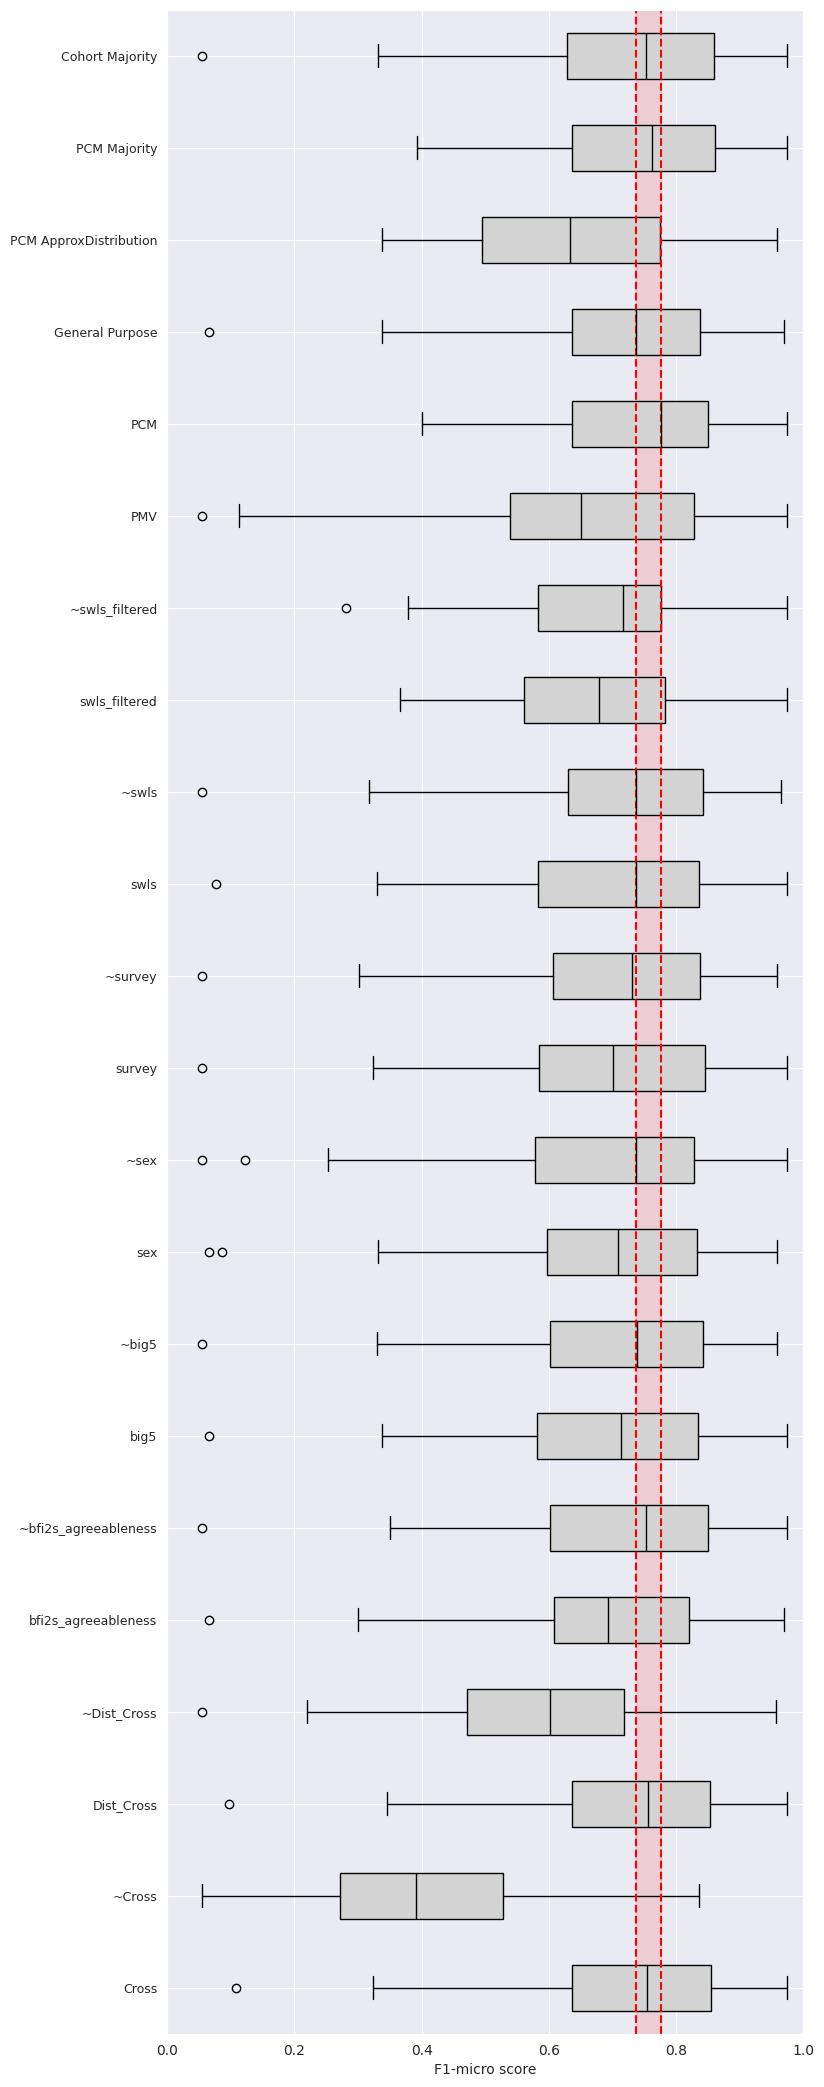

In [12]:
#PersonAI
grouped_personai_scores = make_grouped_scores(all_personai_scores)
gp_median = all_personai_scores[all_personai_scores["model"] == "General Purpose"]["f1_micro"].median()
pcm_median = all_personai_scores[all_personai_scores["model"] == "PCM"]["f1_micro"].median()

pd.DataFrame({
    model: pd.Series(values)
    for model, values in zip(grouped_personai_scores["model"], grouped_personai_scores["f1_micro"])
}).describe().to_csv(
    "../figures/performance_comparison_fig4/performance_comparison_fig4_personai.csv"
)

fig, ax = plt.subplots(figsize=(12, 22))

bp = ax.boxplot(
    grouped_personai_scores["f1_micro"],
    vert=False,
    labels=grouped_personai_scores["model"],
    patch_artist=True,
    boxprops=dict(facecolor="lightgray", color="black"),
    medianprops=dict(color="black"),
    whiskerprops=dict(color="black"),
    capprops=dict(color="black")
)

ax.axvspan(gp_median, pcm_median, color="red", alpha=0.12)
ax.axvline(gp_median, color="red", linestyle="--", linewidth=1.5)
ax.axvline(pcm_median, color="red", linestyle="--", linewidth=1.5)

ax.set_xlabel("F1-micro score")
ax.set_xlim(0, 1)
ax.tick_params(axis="y", labelsize=9)

plt.subplots_adjust(left=0.45, right=0.98, top=0.98, bottom=0.06)
#plt.title("PersonAI Wrong Cluster Performance Comparison")
plt.savefig("../figures/performance_comparison_fig4/performance_comparison_fig4_personai.pdf", dpi=300, bbox_inches="tight")
plt.show()

grouped_personai_scores.describe().to_csv("../figures/performance_comparison_fig4/performance_comparison_fig4_personai.csv")

/tmp/ipykernel_3680/3521716305.py:15: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = ax.boxplot(


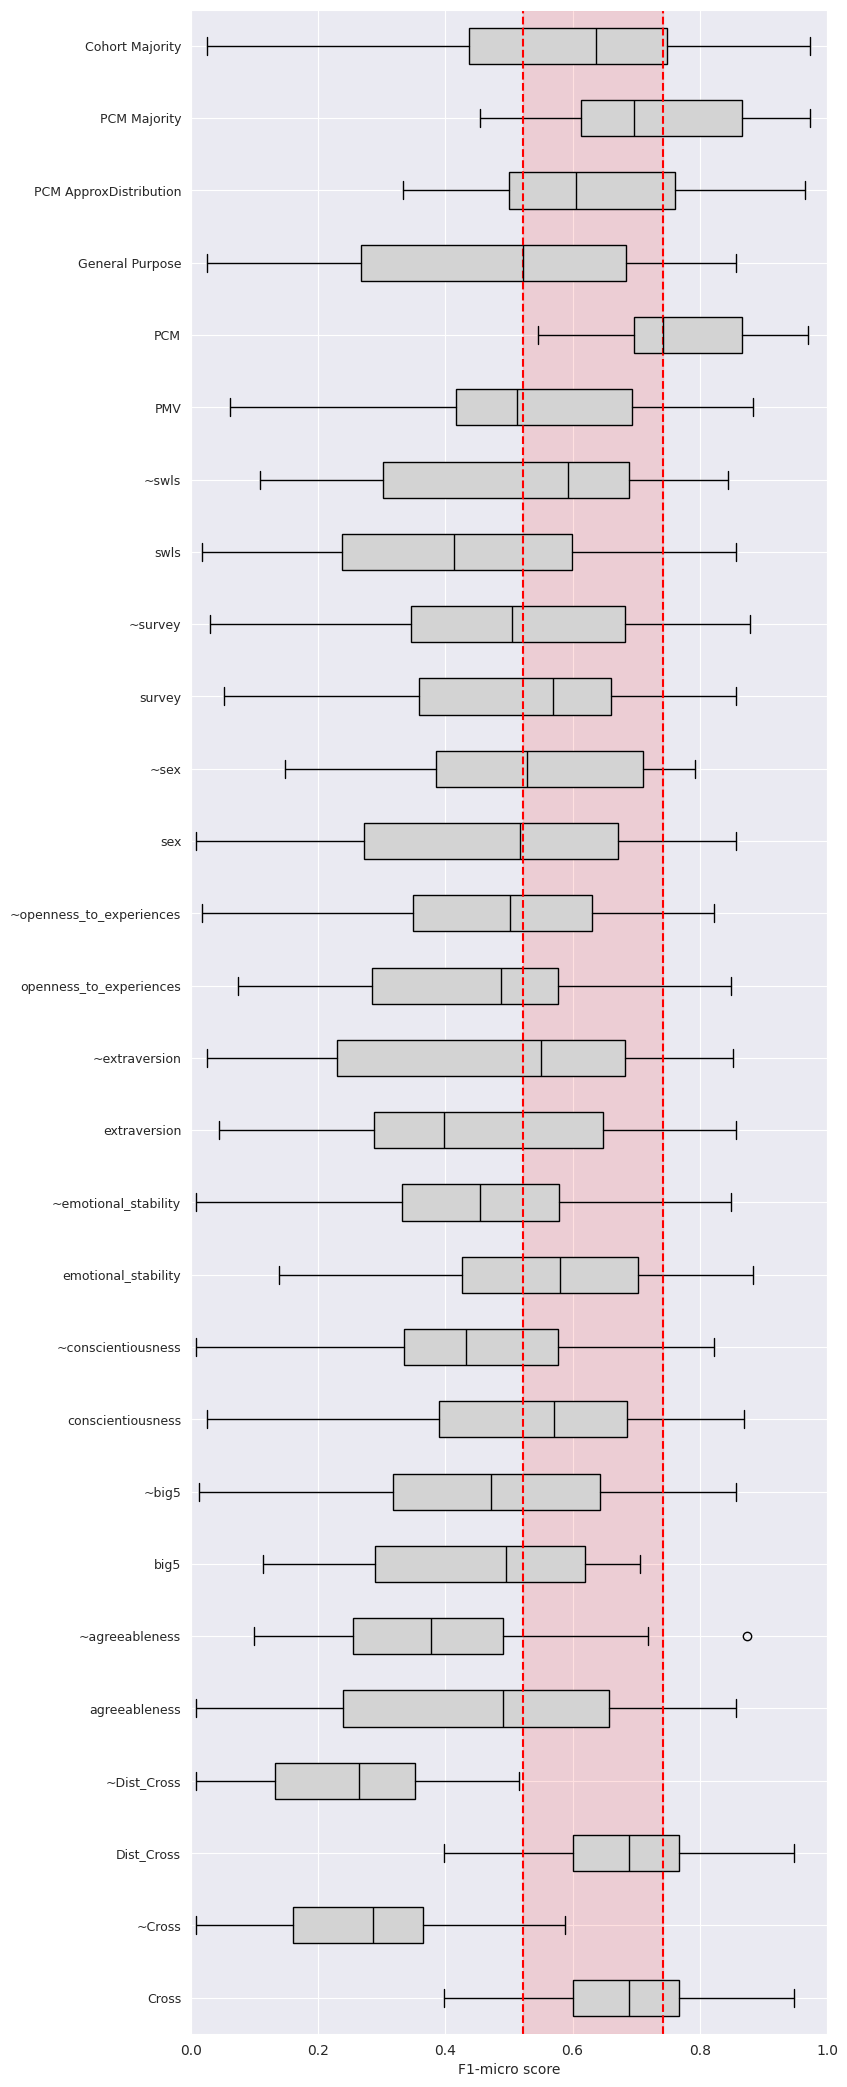

In [13]:
#DORN
grouped_dorn_scores = make_grouped_scores(all_dorn_scores)
gp_median = all_dorn_scores[all_dorn_scores["model"] == "General Purpose"]["f1_micro"].median()
pcm_median = all_dorn_scores[all_dorn_scores["model"] == "PCM"]["f1_micro"].median()

pd.DataFrame({
    model: pd.Series(values)
    for model, values in zip(grouped_dorn_scores["model"], grouped_dorn_scores["f1_micro"])
}).describe().to_csv(
    "../figures/performance_comparison_fig4/performance_comparison_fig4_dorn.csv"
)

fig, ax = plt.subplots(figsize=(12, 22))

bp = ax.boxplot(
    grouped_dorn_scores["f1_micro"],
    vert=False,
    labels=grouped_dorn_scores["model"],
    patch_artist=True,
    boxprops=dict(facecolor="lightgray", color="black"),
    medianprops=dict(color="black"),
    whiskerprops=dict(color="black"),
    capprops=dict(color="black")
)

ax.axvspan(gp_median, pcm_median, color="red", alpha=0.12)
ax.axvline(gp_median, color="red", linestyle="--", linewidth=1.5)
ax.axvline(pcm_median, color="red", linestyle="--", linewidth=1.5)

ax.set_xlabel("F1-micro score")
ax.set_xlim(0, 1)
ax.tick_params(axis="y", labelsize=9)

plt.subplots_adjust(left=0.45, right=0.98, top=0.98, bottom=0.06)
#plt.title("DORN Wrong Cluster Performance Comparison")
plt.savefig("../figures/performance_comparison_fig4/performance_comparison_fig4_dorn.pdf", dpi=300, bbox_inches="tight")
plt.show()
grouped_dorn_scores.describe().to_csv("../figures/performance_comparison_fig4/performance_comparison_fig4_personai.csv")


### Match paper style

/tmp/ipykernel_42053/1307521329.py:35: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = ax.boxplot(
/tmp/ipykernel_42053/1307521329.py:35: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = ax.boxplot(


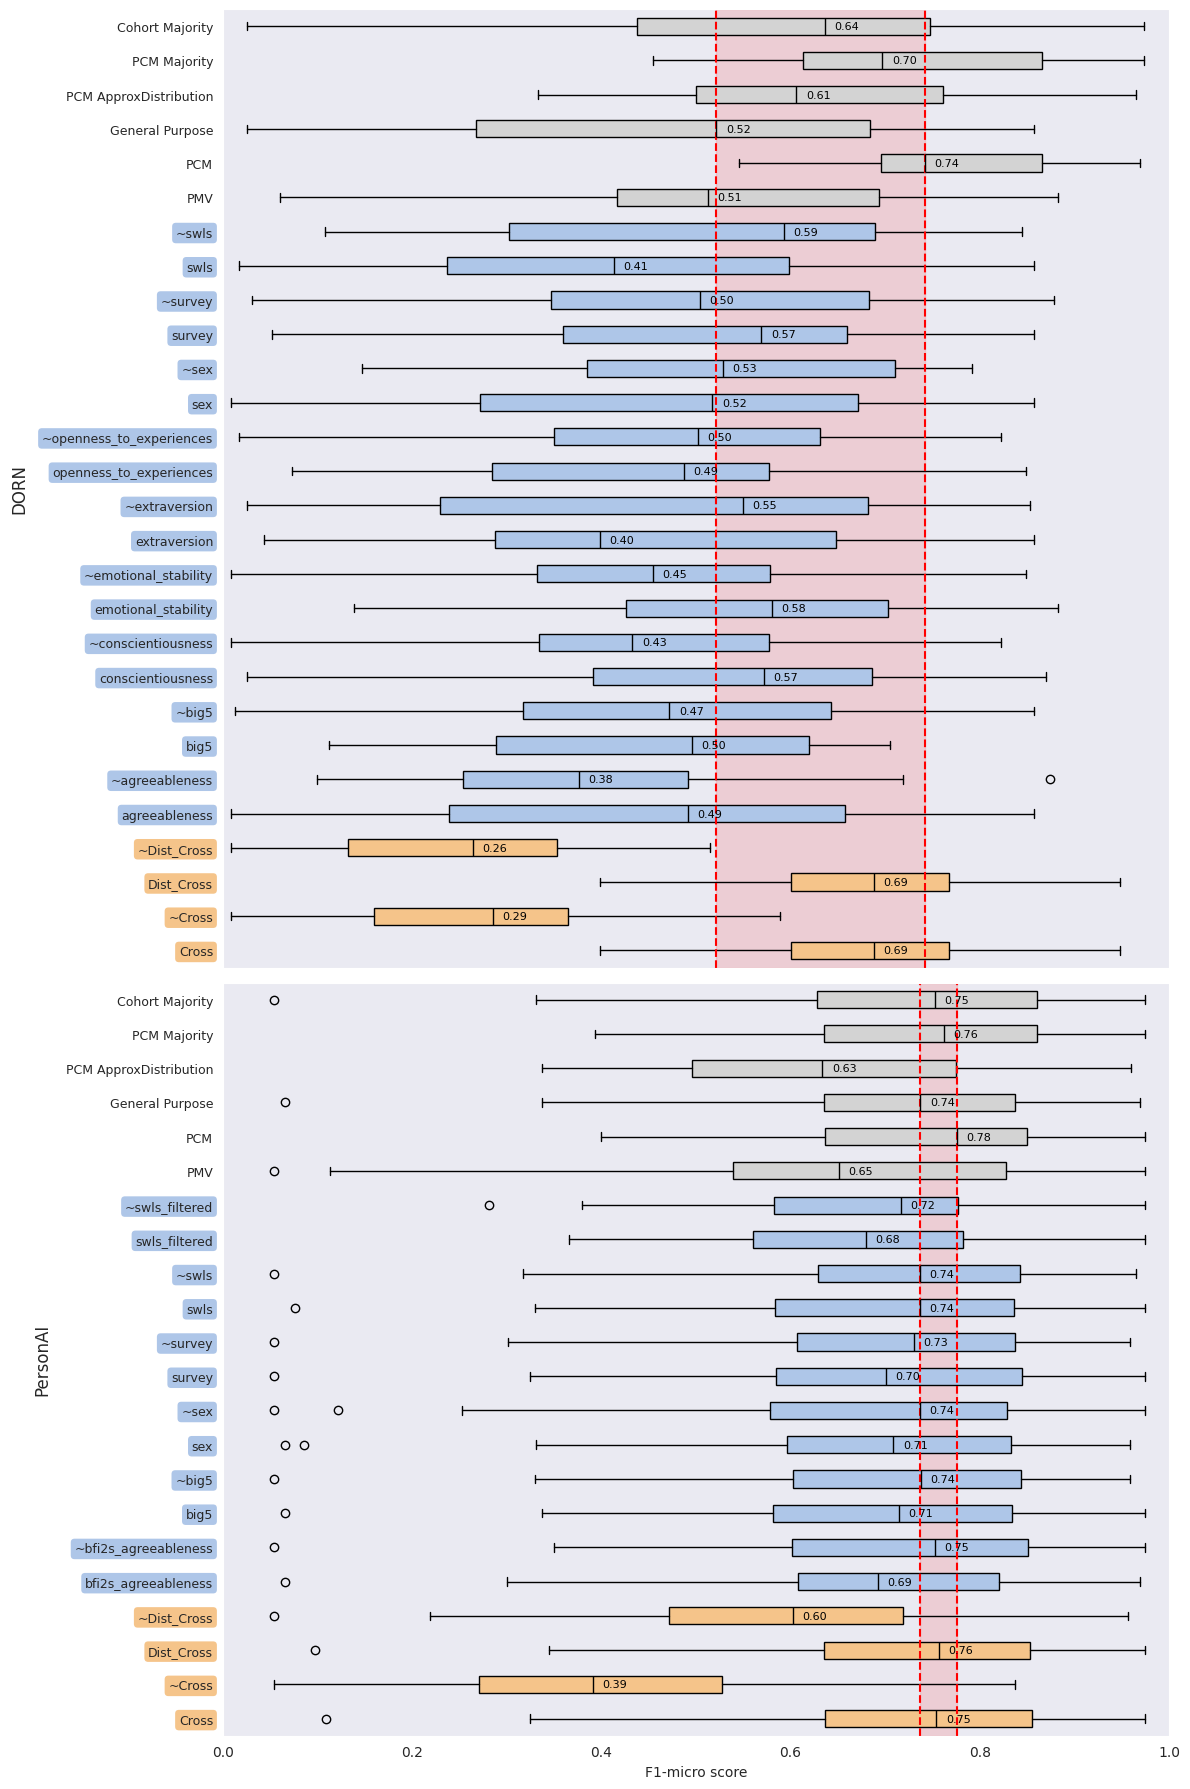

In [9]:
import numpy as np
datasets = {
    "DORN":     all_dorn_scores,
    "PersonAI": all_personai_scores    
}

blue_models   = [ "survey", "~survey", "big5", "~big5", "~all", "all", "sex", "~sex", "~openness_to_experiences", "openness_to_experiences", "agreeableness", "~agreeableness", "conscientiousness", "~conscientiousness", "emotional_stability", "~emotional_stability", "extraversion", "~extraversion", "swls", "~swls", "swls_filtered", "~swls_filtered", "bfi2s_extraversion", "~bfi2s_extraversion", "bfi2s_openness", "~bfi2s_openness", "bfi2s_agreeableness", "~bfi2s_agreeableness", "bfi2s_conscientiousness", "~bfi2s_conscientiousness", "bfi2s_emotional_stability", "~bfi2s_emotional_stability", "bfi2s_negative_emotionality", "~bfi2s_negative_emotionality"]   #cold exps
orange_models = ["Cross", "~Cross", "Dist_Cross", "~Dist_Cross"]  #warm exps

color_map = {m: "#AEC6E8" for m in blue_models}
color_map.update({m: "#F5C48A" for m in orange_models})

#---------saving csv
combined_summary = {}
for dataset_name, scores in datasets.items():
    gs = make_grouped_scores(scores)
    for model, values in zip(gs["model"], gs["f1_micro"]):
        combined_summary[(dataset_name, model)] = pd.Series(values)

pd.DataFrame(combined_summary).describe().to_csv(
    "../figures/performance_comparison_fig4/performance_comparison_fig4_combined.csv"
)


fig, axes = plt.subplots(
    len(datasets), 1, figsize=(12, 18), sharex=True,
    gridspec_kw={"height_ratios": [len(make_grouped_scores(s)) for s in datasets.values()]}
)

for ax, (title, scores) in zip(axes, datasets.items()):
    gs = make_grouped_scores(scores)
    gp_med = scores[scores["model"] == "General Purpose"]["f1_micro"].median()
    pcm_med = scores[scores["model"] == "PCM"]["f1_micro"].median()

    bp = ax.boxplot(
        gs["f1_micro"], vert=False, labels=gs["model"],
        patch_artist=True,
        boxprops=dict(facecolor="lightgray", color="black"),
        medianprops=dict(color="black"),
        whiskerprops=dict(color="black"),
        capprops=dict(color="black")
    )

    for patch, label in zip(bp["boxes"], gs["model"]):
        patch.set_facecolor(color_map.get(label, "lightgray"))

    ax.axvspan(gp_med, pcm_med, color="red", alpha=0.12)
    ax.axvline(gp_med,  color="red", linestyle="--", linewidth=1.5)
    ax.axvline(pcm_med, color="red", linestyle="--", linewidth=1.5)
    ax.set_xlim(0, 1)
    ax.set_ylabel(title, fontsize=12, rotation=90, labelpad=10)
    ax.tick_params(axis="y", labelsize=9)

    for ticklabel in ax.get_yticklabels():
        label = ticklabel.get_text()
        if label in color_map:
            ticklabel.set_bbox(dict(
                facecolor=color_map[label],
                edgecolor="none",
                boxstyle="round,pad=0.3"
            ))

    #median text inside box
    for i, (model, values) in enumerate(zip(gs["model"], gs["f1_micro"])):
        median_val = np.median(values)
        ax.text(
            median_val + 0.01,
            i + 1,
            f"{median_val:.2f}",
            ha="left",
            va="center",
            fontsize=8,
            color="black",
            fontweight="normal"
        )

    ax.grid(False)

axes[-1].set_xlabel("F1-micro score")
#fig.suptitle("Performance Comparison", fontsize=13, y=0.99)
plt.tight_layout()
plt.grid(False)
plt.savefig("../figures/performance_comparison_fig4/performance_comparison_fig4_combined.pdf", dpi=300, bbox_inches="tight")
plt.show()